LA SOLUTION SE TROUVE ICI
---
Conmme moi je n'ai pas de Clé chat payante, j'utilise GROQ.

In [ ]:
import os
from typing import TypedDict, Literal, List, Sequence, Annotated
from langchain.tools import tool
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph import StateGraph, START, END, add_messages
from langgraph.prebuilt import ToolNode
from langchain_groq import ChatGroq
from IPython.display import Image, display


os.environ["GROQ_API_KEY"] = "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"

llm = ChatGroq(
    model="llama-3.3-70b-versatile",
    temperature=0
)

Partie 1 - Workflow RH de base (State & Fonctions)
---

In [5]:
# Définition du State RH
class EmployeeState(TypedDict):
    name: str
    salary: float
    age: int
    decision: Literal["std_hr", "forced_hr"]
    result: str

# Nœud d'analyse
def analyze_employee(state: EmployeeState) -> EmployeeState:
    age = state['age']
    salary = state['salary']
    if age <= 30 and salary <= 40000:
        state['decision'] = "std_hr"
    else:
        state['decision'] = "forced_hr"
    print(f"Le dossier de {state['name']} a été analysé")
    return state

# Nœud HR Standard
def standard_hr_process(state: EmployeeState) -> EmployeeState:
    state['result'] = f"Le dossier de {state['name']} a été traité de manière standard"
    print("*" * 80)
    print(f"Le dossier de {state['name']} a été traité de manière standard")
    print("*" * 80)
    return state

# Nœud HR Forcé (Urgente)
def forced_hr_process(state: EmployeeState) -> EmployeeState:
    state['result'] = f"Le dossier de {state['name']} a été traité de manière urgente"
    print("=" * 80)
    print(f"Le dossier de {state['name']} a été traité de manière urgente")
    print("=" * 80)
    return state

# Routeur conditionnel
def router(state: EmployeeState):
    return state['decision']

Partie 1 - Graph RH & Test
---

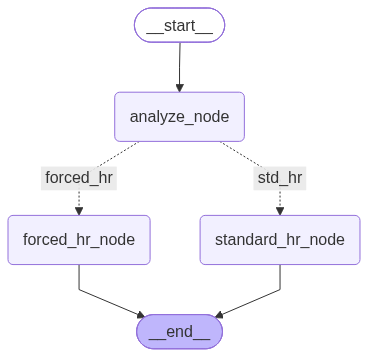

Le dossier de rania a été analysé
********************************************************************************
Le dossier de rania a été traité de manière standard
********************************************************************************


In [6]:
# Construction du graphe RH
workflow_hr = StateGraph(EmployeeState)
workflow_hr.add_node("analyze_node", analyze_employee)
workflow_hr.add_node("standard_hr_node", standard_hr_process)
workflow_hr.add_node("forced_hr_node", forced_hr_process)

workflow_hr.add_edge(START, "analyze_node")
workflow_hr.add_conditional_edges(
    "analyze_node",
    router,
    {
        "std_hr": "standard_hr_node",
        "forced_hr": "forced_hr_node"
    }
)
workflow_hr.add_edge("standard_hr_node", END)
workflow_hr.add_edge("forced_hr_node", END)

graph_hr = workflow_hr.compile()

# Affichage du schéma du graphe RH
display(Image(graph_hr.get_graph().draw_mermaid_png()))

# Test du graphe RH
result_hr = graph_hr.invoke({
    "name": "rania", 
    "age": 25, 
    "salary": 40000
})

Partie 2 - Agent avec Outils (Tools Mathématiques)
---

In [7]:
# Définition des outils (Tools)
@tool
def somme(a: int, b: int) -> int:
    """Add two integers a and b."""
    print(f"Adding {a} to {b}")
    return a + b

@tool
def produit(a: int, b: int) -> int:
    """Multiply two integers a and b."""
    print(f"Multiplying {a} by {b}")
    return a * b

@tool
def qotient(a: int, b: int) -> float:
    """Dividing two integers a and b."""
    print(f"Dividing {a} by {b}")
    return a / b

tools = [somme, produit, qotient]

# Lier le LLM Groq aux outils
llm_with_tools = llm.bind_tools(tools=tools)

# State de l'Agent
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

Nœuds et Routage de l'Agent
---

In [8]:
# Nœud de l'assistant (LLM) - Correction du dictionnaire Python apportée ici
def assistant(state: AgentState) -> dict:
    response = llm_with_tools.invoke(state['messages'])
    print("#" * 40)
    print("LLM invoked")
    return {"messages": [response]}

# Fonction de routage conditionnel
def should_continue(state: AgentState) -> str:
    last_message = state['messages'][-1]
    if hasattr(last_message, 'tool_calls') and last_message.tool_calls:
        return "continue"
    else:
        return "end"

Construction du Graph Agent & Visualisation
---

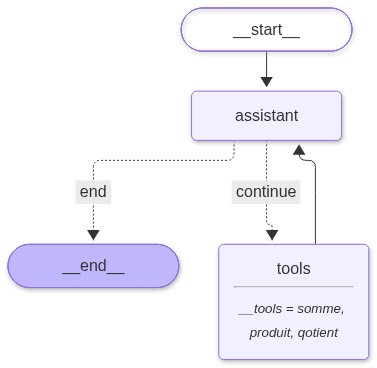

In [9]:
# Graphe Agentique
workflow_agent = StateGraph(AgentState)

workflow_agent.add_node("assistant", assistant)
workflow_agent.add_node("tools", ToolNode(tools=tools))

workflow_agent.add_edge(START, "assistant")
workflow_agent.add_conditional_edges(
    "assistant",
    should_continue,
    {
        "end": END,
        "continue": "tools"
    }
)
workflow_agent.add_edge("tools", "assistant")

graph_agent = workflow_agent.compile()

# Affichage du graphe
display(Image(graph_agent.get_graph().draw_mermaid_png()))

Tests et Streaming de l'Agent
---

In [ ]:
# 1. Mise à jour du modèle Groq disponible et recompilation du graphe
llm = ChatGroq(
    model="llama-3.1-8b-instant",
    temperature=0
)
llm_with_tools = llm.bind_tools(tools=tools)

workflow_agent = StateGraph(AgentState)
workflow_agent.add_node("assistant", assistant)
workflow_agent.add_node("tools", ToolNode(tools=tools))

workflow_agent.add_edge(START, "assistant")
workflow_agent.add_conditional_edges(
    "assistant",
    should_continue,
    {
        "end": END,
        "continue": "tools"
    }
)
workflow_agent.add_edge("tools", "assistant")

graph_agent = workflow_agent.compile()


# 2. Test 1 : Invocation directe avec calcul et proverbe
resp = graph_agent.invoke(
    input={
        "messages": [
            HumanMessage(content="""Compute this expression :
Add 6 to 7 then divide by 2 and multiply by 5.
Puis donne moi un proverbe""")
        ]
    }
)

print("\n--- RÉPONSE FINALE ---")
print(resp['messages'][-1].content)

print("\n" + "="*80 + "\n")


# 3. Test 2 : Exécution avec Streaming (suivi étape par étape)
inputs = {
    "messages": [
        HumanMessage(content="Add 6 to 7 then divide the result by 2. Donne moi un proverbe")
    ]
}

stream = graph_agent.stream(inputs, stream_mode="values")

for s in stream:
    messages = s.get('messages', [])
    if messages:
        last_message = messages[-1]
        if hasattr(last_message, "pretty_print"):
            last_message.pretty_print()
        else:
            print(last_message)

--- TEST INVOCATION ---


BadRequestError: Error code: 400 - {'error': {'message': 'The model `llama3-8b-8192` has been decommissioned and is no longer supported. Please refer to https://console.groq.com/docs/deprecations for a recommendation on which model to use instead.', 'type': 'invalid_request_error', 'code': 'model_decommissioned'}}

Pour cette partie en haut, j'ai tout essayé, il ya toujours des erreur, je ne comprends pas pourquoi. Je vais la laisser pour continuer le reste et la terminer après.

Tp6_RAG_Agentique.ipynb
---

In [17]:
import os
import logging
from typing import TypedDict, Annotated, Sequence, Literal
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_community.vectorstores import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_groq import ChatGroq
from langchain.tools import tool
from langgraph.graph import StateGraph, START, END, add_messages
from langgraph.prebuilt import ToolNode
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, BaseMessage
from IPython.display import Markdown, Image, display

# Clé Groq
os.environ["GROQ_API_KEY"] = "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"

Chargement des documents et Text Splitting (Gratuit)
---

In [25]:
# Utilise le chemin exact correspondant à l'emplacement de tes fichiers PDF
import os

# Vérifions d'abord si Python voit le dossier
folder_path = "./src/tp6_agentic/ressources/"  # ou "./ressources/" selon où tu l'as placé

if os.path.exists(folder_path):
    print(f"📁 Fichiers trouvés dans le dossier : {os.listdir(folder_path)}")
else:
    print(f"❌ Le dossier {folder_path} n'existe pas à cet emplacement !")

# Chargement des PDF
loader = PyPDFDirectoryLoader(path=folder_path)
ai_initiative_chunks = loader.load_and_split(text_splitter=text_splitter)

print(f"✅ Nombre de chunks créés : {len(ai_initiative_chunks)}")

❌ Le dossier ./src/tp6_agentic/ressources/ n'existe pas à cet emplacement !
✅ Nombre de chunks créés : 0
